In [2]:
# Instalação, caso necessário
!pip install ucimlrepo -q

# Importação das bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)


In [3]:
# Buscar dataset Adult
adult = fetch_ucirepo(id=2)

# Separar atributos e variável-alvo
X = adult.data.features
y = adult.data.targets

# Unir os dados em um único DataFrame
dataset = pd.concat([X, y], axis=1)

# Remover espaços dos nomes das colunas
dataset.columns = dataset.columns.str.strip()

# Visualizar os primeiros registros
display(dataset.head())

# Verificar dimensões
print("Dimensões do dataset:", dataset.shape)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


Dimensões do dataset: (48842, 15)


In [4]:
# Informações gerais
dataset.info()

# Estatísticas descritivas
display(dataset.describe().round(2))

# Verificar valores ausentes
print(dataset.isnull().sum())

# Verificar distribuição da variável-alvo
target_column = y.columns[0]

print(dataset[target_column].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.00,48842.00,48842.00,48842.00,48842.0,48842.00
mean,38.64,189664.13,10.08,1079.07,87.5,40.42
std,13.71,105604.03,2.57,7452.02,403.0,12.39
min,17.00,12285.00,1.00,0.00,0.0,1.00
25%,28.00,117550.50,9.00,0.00,0.0,40.00
50%,37.00,178144.50,10.00,0.00,0.0,40.00
75%,48.00,237642.00,12.00,0.00,0.0,45.00
max,90.00,1490400.00,16.00,99999.00,4356.0,99.00


age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64
income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64


In [5]:
# Remover espaços dos valores textuais
for col in dataset.select_dtypes(include="object").columns:
    dataset[col] = dataset[col].str.strip()

# Remover a coluna fnlwgt
dataset = dataset.drop(columns=["fnlwgt"], errors="ignore")

# Substituir '?' por valores ausentes
dataset = dataset.replace("?", np.nan)

# Identificar a variável-alvo
target_column = target_column.strip()

# Limpar a variável-alvo
dataset[target_column] = (
    dataset[target_column]
    .astype(str)
    .str.strip()
    .str.replace(r"\.$", "", regex=True)
)

# Remover registros sem classificação de renda
dataset = dataset.dropna(subset=[target_column])

# Separar variáveis independentes e dependente
X = dataset.drop(columns=[target_column])
y = dataset[target_column]

# Verificar as colunas utilizadas
print("Variáveis independentes:")
print(X.columns.tolist())

print("\nVariável dependente:")
print(y.name)

print("\nDimensões de X:", X.shape)
print("Dimensões de y:", y.shape)

Variáveis independentes:
['age', 'workclass', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']

Variável dependente:
income

Dimensões de X: (48842, 13)
Dimensões de y: (48842,)


In [6]:
# Identificar colunas numéricas
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identificar colunas categóricas
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Variáveis numéricas:", numeric_features)
print("\nVariáveis categóricas:", categorical_features)

Variáveis numéricas: ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Variáveis categóricas: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [7]:
# Tratamento das variáveis numéricas
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Tratamento das variáveis categóricas
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combinar os tratamentos
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [8]:
# Divisão dos dados
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Dados de treinamento:", X_train.shape)
print("Dados de teste:", X_test.shape)

print("\nDistribuição do treinamento:")
print(y_train.value_counts(normalize=True).round(3))

print("\nDistribuição do teste:")
print(y_test.value_counts(normalize=True).round(3))

Dados de treinamento: (34189, 13)
Dados de teste: (14653, 13)

Distribuição do treinamento:
income
<=50K    0.761
>50K     0.239
Name: proportion, dtype: float64

Distribuição do teste:
income
<=50K    0.761
>50K     0.239
Name: proportion, dtype: float64


In [9]:
# Criar o classificador
clf = DecisionTreeClassifier(
    criterion="entropy",
    min_samples_leaf=1,
    random_state=42
)

# Criar pipeline completo
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", clf)
])

# Treinar o modelo
model.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [10]:
# Previsões
y_pred = model.predict(X_test)

# Visualizar algumas previsões
resultados = pd.DataFrame({
    "Valor Real": y_test.values,
    "Valor Previsto": y_pred
})

display(resultados.head(20))

,Valor Real,Valor Previsto
0,<=50K,<=50K
1,<=50K,<=50K
2,<=50K,<=50K
3,<=50K,<=50K
4,<=50K,<=50K
5,<=50K,<=50K
6,>50K,<=50K
7,<=50K,<=50K
8,<=50K,<=50K
9,<=50K,>50K


In [11]:
# Calcular métricas
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    pos_label=">50K"
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label=">50K"
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label=">50K"
)

# Exibir resultados
print("AVALIAÇÃO DO MODELO - DECISION TREE")
print("-----------------------------------")

print(f"Acurácia:  {accuracy:.4f}")
print(f"Precisão:  {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred))

AVALIAÇÃO DO MODELO - DECISION TREE
-----------------------------------
Acurácia:  0.8230
Precisão:  0.6316
Recall:    0.6244
F1-Score:  0.6279

Relatório de classificação:
              precision    recall  f1-score   support

       <=50K       0.88      0.89      0.88     11147
        >50K       0.63      0.62      0.63      3506

    accuracy                           0.82     14653
   macro avg       0.76      0.75      0.76     14653
weighted avg       0.82      0.82      0.82     14653



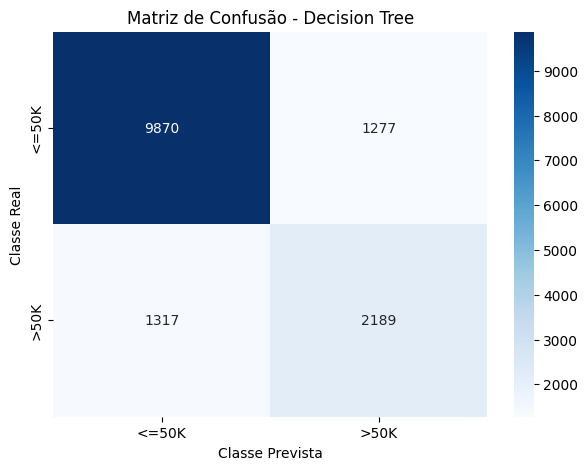

In [12]:
# Gerar matriz de confusão
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["<=50K", ">50K"]
)

# Visualização
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)

plt.title("Matriz de Confusão - Decision Tree")
plt.xlabel("Classe Prevista")
plt.ylabel("Classe Real")
plt.show()

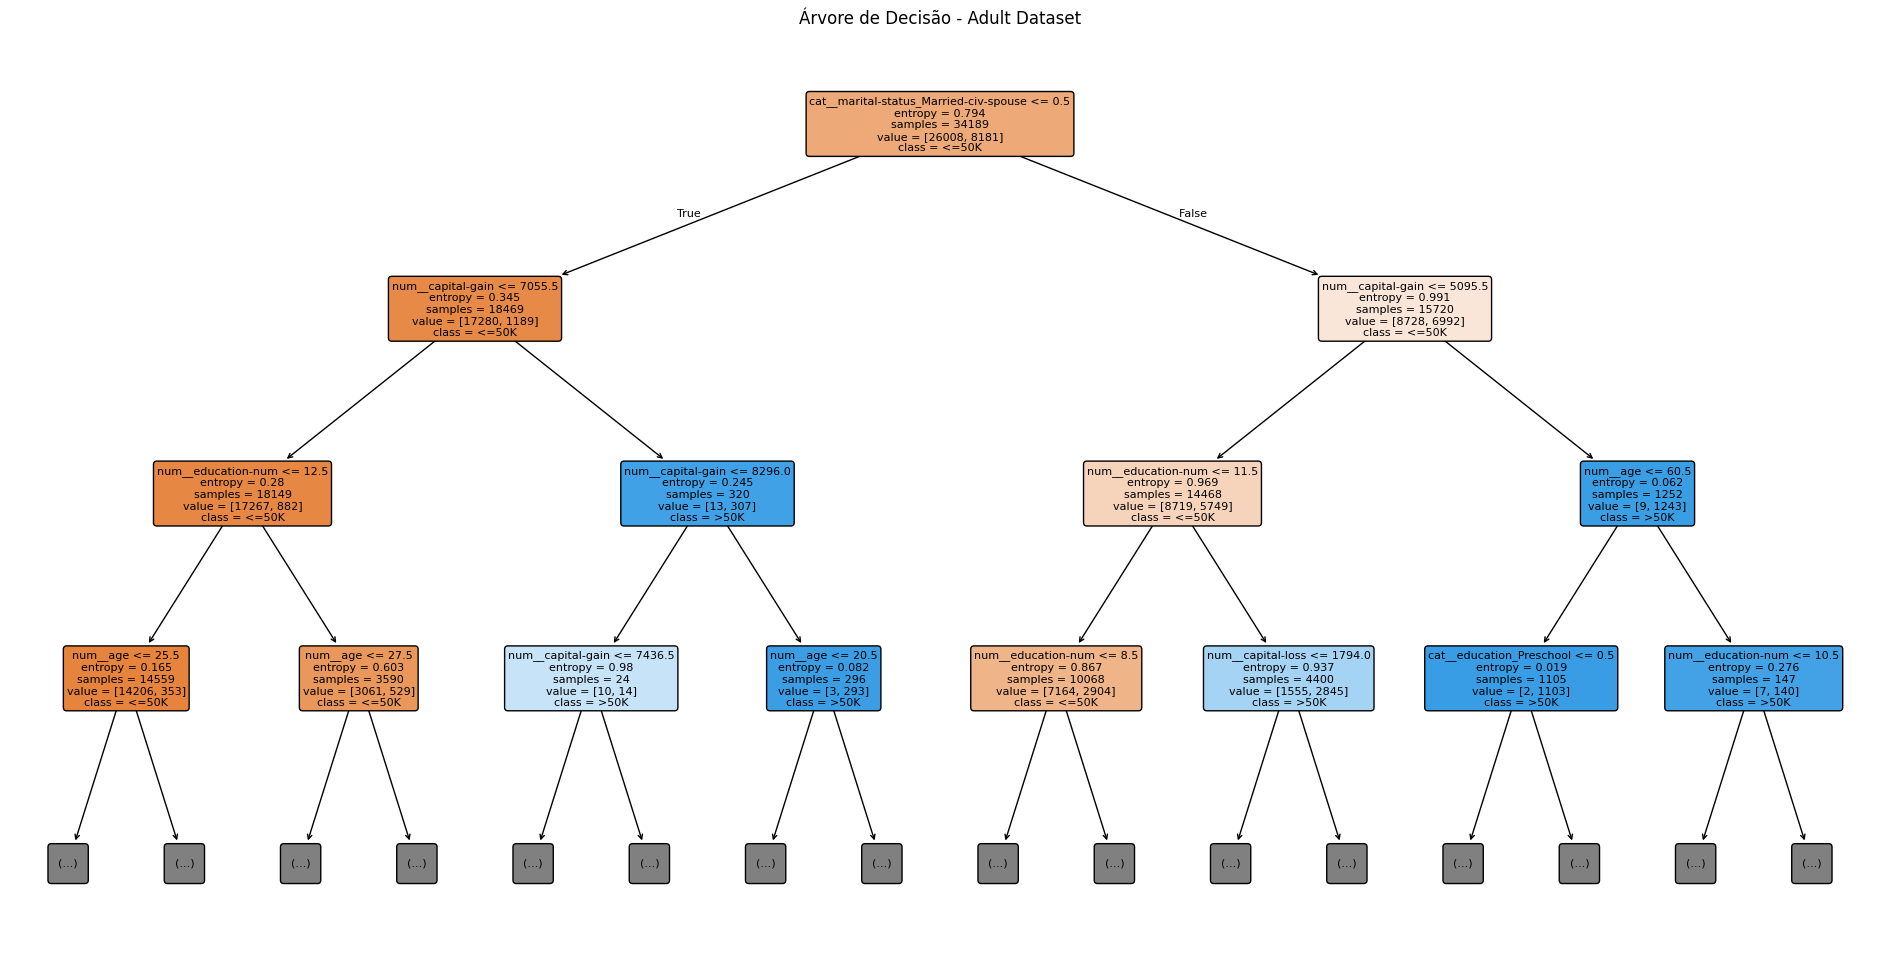

In [14]:
# Recuperar nomes das variáveis transformadas
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Recuperar classificador treinado
tree_model = model.named_steps["classifier"]

# Visualizar árvore
plt.figure(figsize=(24, 12))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Árvore de Decisão - Adult Dataset")
plt.show()

,Variável,Importância
31,cat__marital-status_Married-civ-spouse,0.2071
0,num__age,0.1812
2,num__capital-gain,0.1261
1,num__education-num,0.0997
4,num__hours-per-week,0.0960
3,num__capital-loss,0.0429
39,cat__occupation_Exec-managerial,0.0135
8,cat__workclass_Private,0.0133
47,cat__occupation_Sales,0.0121
38,cat__occupation_Craft-repair,0.0100


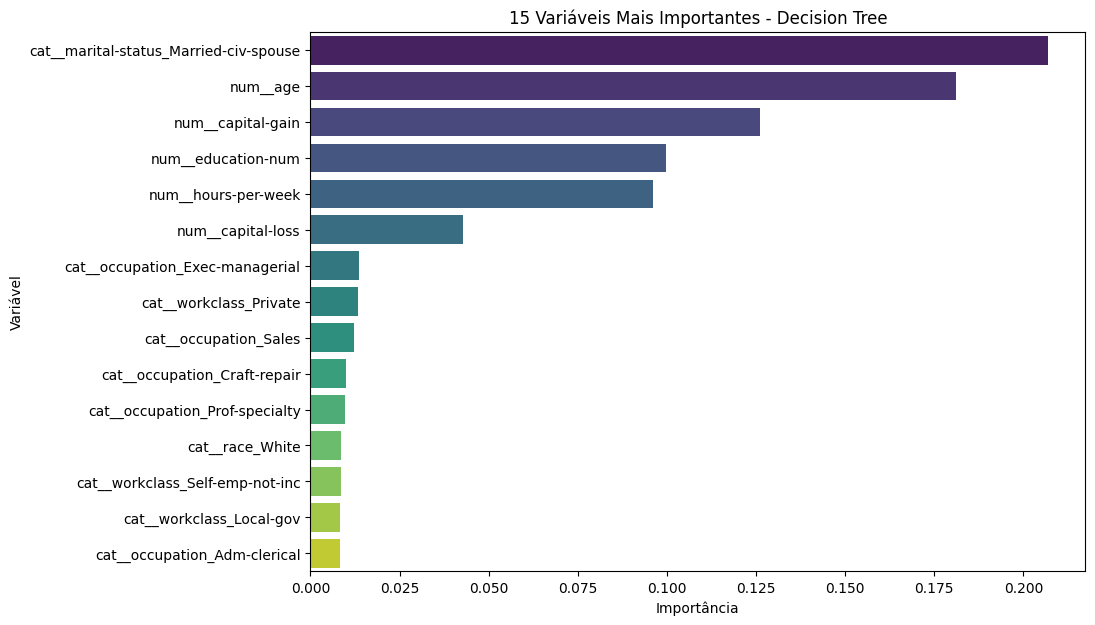

In [15]:
# Obter importância das variáveis
importances = tree_model.feature_importances_

# Criar DataFrame
feature_importance = pd.DataFrame({
    "Variável": feature_names,
    "Importância": importances
})

# Ordenar por importância
feature_importance = feature_importance.sort_values(
    by="Importância",
    ascending=False
)

# Exibir as 15 variáveis mais importantes
display(feature_importance.head(15).round(4))
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importância",
    y="Variável",
    hue="Variável",
    legend=False,
    palette="viridis"
)

plt.title("15 Variáveis Mais Importantes - Decision Tree")
plt.xlabel("Importância")
plt.ylabel("Variável")
plt.show()